In [1]:
# %pip install -q numpy pandas matplotlib seaborn scikit-learn xgboost

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split,KFold,cross_validate,GridSearchCV

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer  
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.impute import SimpleImputer
from xgboost import XGBRegressor

from sklearn.linear_model import LinearRegression,Ridge,Lasso

from sklearn.ensemble import RandomForestRegressor,HistGradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)  

In [3]:
# confguration 
pd.set_option("display.max_columns",None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
sns.set_theme(style="darkgrid")

# below is the setting for the data fonst style and arrangements stuff
plt.rcParams.update({
    "axes.titlesize":10,
    "axes.labelsize": 9 ,
    "xtick.labelsize":8,
    "ytick.labelsize": 8
})

RANDOM_STATE=42
CSV_PATH="housing.csv"
TARGET_COL="median_house_value"

In [4]:
# loading the csv dataset

df=pd.read_csv(CSV_PATH)

In [5]:
print(df.shape)

(20640, 10)


In [6]:
# EXPLOIRATORY DATA ANALYSIS(EDA)

df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

In [7]:
# basix dataset overview
df.info()

#  here the total_bedrom column have some values missin

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [8]:
# we have to convert the object value to munerical so that the model could understand

num_cols=df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols=df.select_dtypes(include=["object"]).columns.tolist()

print("targer column==> ",TARGET_COL)
print("numerical column==> ",num_cols)
print("catagorical column==> ",cat_cols)

targer column==>  median_house_value
numerical column==>  ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']
catagorical column==>  ['ocean_proximity']


In [9]:
# missing values   analysis 
#  here we will find the missing or null values 
print("\n missing values==>")
print(df.isna().sum())

# 207 missing values


 missing values==>
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [10]:
# checking the placeholder values that overshados the not_null check in the columns / data
for col in df.columns:
    print(df[col].value_counts().head(20))
    
    # here this will help to remove the placeholder which eventually hides the not_null check factor
    # thus removing the placeholder

longitude
-118.310    162
-118.300    160
-118.290    148
-118.270    144
-118.320    142
-118.280    141
-118.350    140
-118.360    138
-118.190    135
-118.250    128
-118.370    128
-118.200    126
-118.140    125
-118.260    121
-118.130    121
-118.180    120
-118.340    119
-118.210    118
-118.150    116
-118.120    112
Name: count, dtype: int64
latitude
34.060    244
34.050    236
34.080    234
34.070    231
34.040    221
34.090    212
34.020    208
34.100    203
34.030    193
33.930    181
33.940    175
33.970    172
33.990    168
33.880    164
33.980    162
34.110    162
34.160    159
34.120    158
34.150    157
34.010    156
Name: count, dtype: int64
housing_median_age
52.000    1273
36.000     862
35.000     824
16.000     771
17.000     698
34.000     689
26.000     619
33.000     615
18.000     570
25.000     566
32.000     565
37.000     537
15.000     512
19.000     502
27.000     488
24.000     478
30.000     476
28.000     471
20.000     465
29.000     461
Name: coun

In [11]:
# we will not take the median value and replace it with the null value or no present value , this will result in data leakage
# we will split the data into training data and test data , find the median value of that particular col in the training data, then replace all the missing values with the median value in the traingn and testing data
# this will prevent data leakage

In [12]:
# checing duplicate
duplicate_mask=df.duplicated()
num_duplicates=duplicate_mask.sum()
print("duplicate data roe:" , num_duplicates)

# remove duplicate after fidnding
df=df.drop_duplicates()

duplicate data roe: 0


In [13]:
# descriptive stat
df[num_cols].describe().T
# will give the max min mean , basic stats of the data
# for checking the data is skewed or not
# if mean val > median  val ==> chance that the data is skewed

,count,mean,std,min,25%,50%,75%,max
longitude,20640.000,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
latitude,20640.000,35.632,2.136,32.540,33.930,34.260,37.710,41.950
housing_median_age,20640.000,28.639,12.586,1.000,18.000,29.000,37.000,52.000
total_rooms,20640.000,2635.763,2181.615,2.000,1447.750,2127.000,3148.000,39320.000
total_bedrooms,20433.000,537.871,421.385,1.000,296.000,435.000,647.000,6445.000
population,20640.000,1425.477,1132.462,3.000,787.000,1166.000,1725.000,35682.000
households,20640.000,499.540,382.330,1.000,280.000,409.000,605.000,6082.000
median_income,20640.000,3.871,1.900,0.500,2.563,3.535,4.743,15.000
median_house_value,20640.000,206855.817,115395.616,14999.000,119600.000,179700.000,264725.000,500001.000


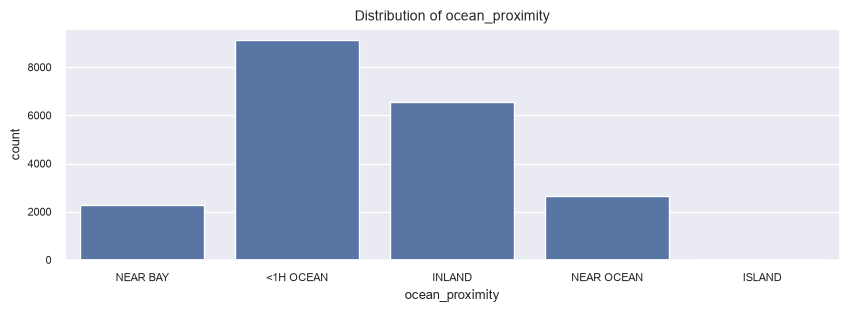

In [14]:
#countplot for the categorical columns
for col in cat_cols:
    plt.figure(figsize=(10,3))  
    sns.countplot(x=col,data=df)
    plt.title(f"Distribution of {col}")
    plt.show()
    
    # graph plot for the categories in the ocean_[roximity]

In [15]:
# for actual value
print(df[col].value_counts())

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


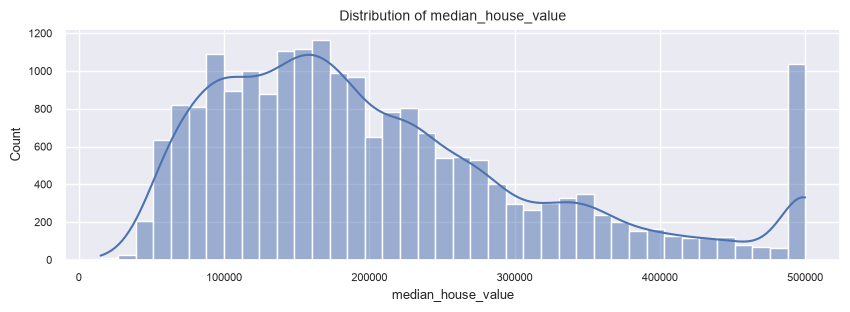

In [16]:
# distribution for target column

plt.figure(figsize=(10,3))  
sns.histplot(df[TARGET_COL],bins=40,kde=True)
plt.title(f"Distribution of {TARGET_COL}")
plt.show()

# here the last strike of the bar shows the hiher cap

In [17]:
df[TARGET_COL].value_counts()
# here the higher cap exist so model can make mistakes
# this data is no so clean

median_house_value
500001.000    965
137500.000    122
162500.000    117
112500.000    103
187500.000     93
             ... 
34200.000       1
46200.000       1
352000.000      1
307900.000      1
385200.000      1
Name: count, Length: 3842, dtype: int64

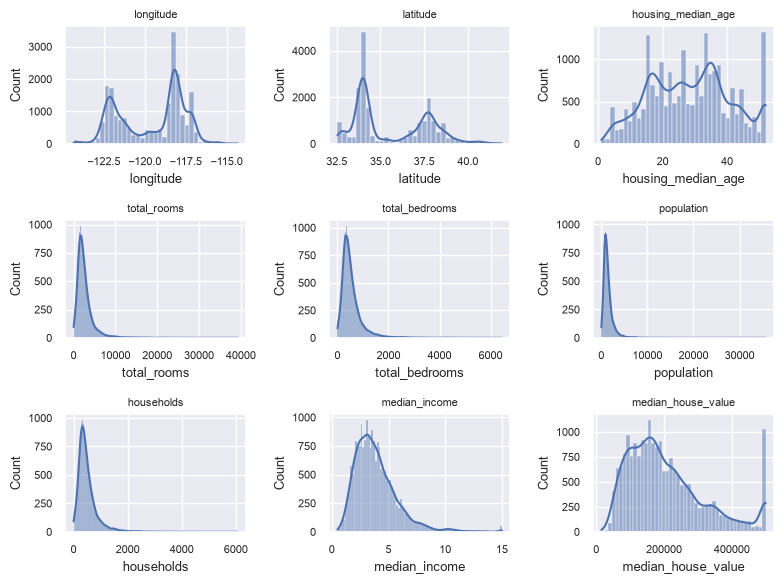

In [18]:
# distribution plot for numerical columns

#  below making 3x3 subplot

fig,axes =plt.subplots(3,3,figsize=(8,6))
axes=axes.flatten()
for i,col in enumerate(num_cols):
    sns.histplot(df[col],kde=True,ax=axes[i])
    axes[i].set_title(col,fontsize=8)
    
plt.tight_layout()
plt.show()

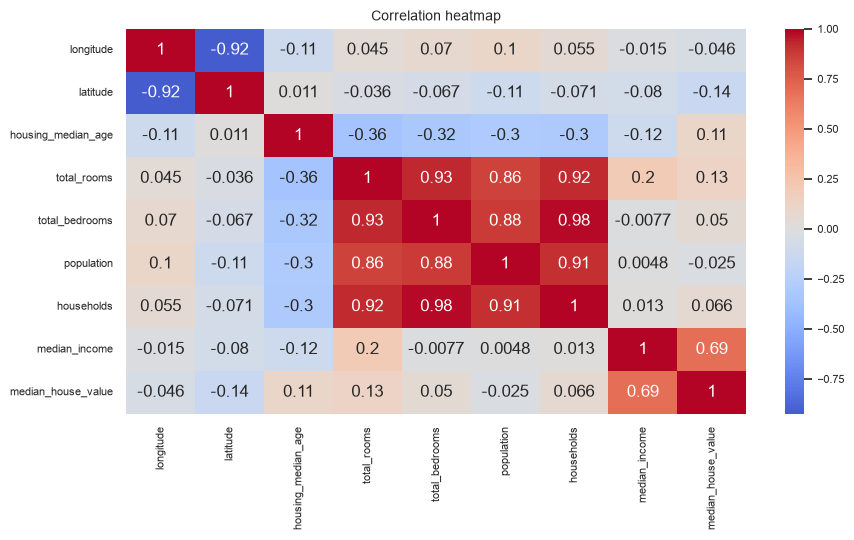

In [19]:
#    now drawint the corelation map, that will give correalation between different col
plt.figure(figsize=(10,5))
sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    cmap="coolwarm",
    center=0
)
plt.title("Correlation heatmap")
plt.show()

# +1 positive correlation
# -1 negative correlation


In [20]:
# to fnd the correlation with the target column

corr_with_target=df[num_cols].corr()[TARGET_COL].sort_values(ascending=False)
print("correlation with target col::")
print(corr_with_target)

correlation with target col::
median_house_value    1.000
median_income         0.688
total_rooms           0.134
housing_median_age    0.106
households            0.066
total_bedrooms        0.050
population           -0.025
longitude            -0.046
latitude             -0.144
Name: median_house_value, dtype: float64


In [21]:
#  NOW DATA PREPROCESSING ==>

In [22]:
# 1.seperating the data into features ans target
X=df.drop(columns=[TARGET_COL])   # removes target_col from the col and stored in x 
y=df[TARGET_COL]     # putting the target_val in y

In [23]:
X.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,NEAR BAY
1,-122.220,37.860,21.000,7099.000,1106.000,2401.000,1138.000,8.301,NEAR BAY
2,-122.240,37.850,52.000,1467.000,190.000,496.000,177.000,7.257,NEAR BAY
3,-122.250,37.850,52.000,1274.000,235.000,558.000,219.000,5.643,NEAR BAY
4,-122.250,37.850,52.000,1627.000,280.000,565.000,259.000,3.846,NEAR BAY


In [24]:
y.head()

0   452600.000
1   358500.000
2   352100.000
3   341300.000
4   342200.000
Name: median_house_value, dtype: float64

In [25]:
# data leakge==> problem where the information of test datasets leaked in the train datasets
# THUS PERFORMING TRAIN AND TEST DATASETS SPLITTING

X_train,X_test,y_train,y_test= train_test_split(
    X,
    y,
    test_size=0.2,   # herre 20% data convert into test datasets,and remaingn 80% will become train datatsets
    random_state=RANDOM_STATE    
)

In [26]:
print("Training shape",X_train.shape)
print("Testing shape",X_test.shape)

Training shape (16512, 9)
Testing shape (4128, 9)


In [27]:
# PRE PROCESSING PIPE LINE

In [28]:
numerical_feature=X_train.select_dtypes(include={np.number}).columns.tolist()
catagorical_feature=X_train.select_dtypes(exclude={np.number}).columns.tolist()
numerical_feature
# catagorical_feature
# this will create a dataframe for numericial_features
# here numerical features in the form of the list

print("Numerical Features",numerical_feature)
print("Catagorical Features",catagorical_feature)

# the categorical feature and numerical feature will go int different preprocesses


Numerical Features ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Catagorical Features ['ocean_proximity']


In [29]:
# numerical_feature=preprocessing steps

numerical_transformer=Pipeline(
    steps=[
        # thus it implies that the numerical _features should go through the imputer and scaler steps
        # here the missing values of the datasets will get replaced by the median of the train datasets
        ("imputer",SimpleImputer(strategy="median")),
        ("scaler",StandardScaler())
    ]
)


# categorial_feature=preprocessing steps

# thus the categorical_feature go through the imputer and onhot encoding
categorical_transformer=Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="most_frequent")),
        ("onehot",OneHotEncoder(handle_unknown="ignore"))
    ]
)

# preprocessing pipleline

preprocess=ColumnTransformer(
    transformers=[
        ("num",numerical_transformer,numerical_feature),
        ("cat",categorical_transformer,catagorical_feature)
    ]
)

In [30]:
# BASELINE MODEL USING THE LINEAR REGRESSION
baseline_model=Pipeline(
    steps=[
        ("preprocess",preprocess),
        ("model",LinearRegression())
    ]
)

In [31]:
# preprocess the data and train int using the baseline model , linear regression model

baseline_model.fit(X_train,y_train)



Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
                                                   'total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                                   'median_income']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['ocean_proximity'])])),
                ('model', LinearRegression())])

In [32]:
# EVALUATION OF THE BASELINE MODEL (LINEAR REGRESSION MODEL)
#  EVALUATION FOR TRAIN DATASET
train_baseline_model_prediction=baseline_model.predict(X_train)
test_baseline_model_prediction=baseline_model.predict(X_test)

In [33]:
# TRAINING DATASETS ERROR EVALUATIONS

train_baseline_model_rmse=root_mean_squared_error(y_train,train_baseline_model_prediction)
train_baseline_model_mae=mean_absolute_error(y_train,train_baseline_model_prediction)
train_baseline_model_r2=r2_score(y_train,train_baseline_model_prediction)

# here y_train are the actual values , the checking is done with the actuall values and the predicted value



# TEST DATA METRICS
# TESTINF DATASETS ERROR EVALUATIONS

test_baseline_model_rmse = root_mean_squared_error(y_test,test_baseline_model_prediction)
test_baseline_model_mae = mean_absolute_error(y_test,test_baseline_model_prediction)
test_baseline_model_r2 = r2_score(y_test,test_baseline_model_prediction)


In [34]:
# THE PREDICITED VALUS==>
train_baseline_model_prediction[:5]

array([188628.0772436 , 290379.8948687 , 250985.48476349, 146878.07878194,
       165789.41368924])

In [35]:
# THE ACTUAL VALUES==>
y_train[:5]

14196   103000.000
8267    382100.000
17445   172600.000
14265    93400.000
2271     96500.000
Name: median_house_value, dtype: float64

In [36]:
# overall result and errors==>
print("\n ===== TRAIN BASELINE METRICS(LINEAR REGRESSION) =====")
print("RMSE(ROOT MEAN SQUARE ERROR ==>)",train_baseline_model_rmse)
print("MAE(MEAN ABSOLUTE ERRORR) ==>)",train_baseline_model_mae)
print("R2(ROOT SQUARE)==>)",train_baseline_model_r2)


 ===== TRAIN BASELINE METRICS(LINEAR REGRESSION) =====
RMSE(ROOT MEAN SQUARE ERROR ==>) 68433.93736666226
MAE(MEAN ABSOLUTE ERRORR) ==>) 49594.84209472437
R2(ROOT SQUARE)==>) 0.6496648627123223


In [37]:
# RandomForest model training=========>
rf_model = Pipeline(
    steps=[
        ("preprocess", preprocess),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42
        ))
    ]
)


# training the randomForest model====>

rf_model.fit(X_train, y_train)


Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
                                                   'total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                                   'median_income']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['ocean_proximity'])])),
                ('model', RandomForestRegressor(random_state=42))])

In [38]:
# ========RANDOM FORREST MODEL PREDICTIONS===========

# TRAINING AND TESTING THE PREDICTIONS==>
train_rf_prediction = rf_model.predict(X_train)
test_rf_prediction=rf_model.predict(X_test)

In [39]:
# ERROR EVALUATION ON THE TRAIN DATASET 

train_rf_rmse = root_mean_squared_error(y_train,train_rf_prediction)
train_rf_mae = mean_absolute_error(y_train,train_rf_prediction)
train_rf_r2 = r2_score(y_train,train_rf_prediction)


# ERROR EVALUATION ON THE TEST DATASET 

test_rf_rmse = root_mean_squared_error(y_test,test_rf_prediction)
test_rf_mae = mean_absolute_error(y_test,test_rf_prediction)
test_rf_r2 = r2_score(y_test,test_rf_prediction)


In [40]:
# TRAINING MATRIX FOR THE RANDOM FOREST MODEL =====>
print("\n ===== TRAIN RANDOM FOREST MODEL METRICS(RANDOM FOREST MODEL) =====")
print("RMSE(ROOT MEAN SQUARE ERROR ==>",train_rf_mae)
print("MAE(MEAN ABSOLUTE ERRORR) ==>",train_rf_rmse)
print("R2(ROOT SQUARE)==>",train_rf_r2)



 ===== TRAIN RANDOM FOREST MODEL METRICS(RANDOM FOREST MODEL) =====
RMSE(ROOT MEAN SQUARE ERROR ==> 11641.438696705427
MAE(MEAN ABSOLUTE ERRORR) ==> 18073.213368485107
R2(ROOT SQUARE)==> 0.9755650534559848


In [41]:
# CREATING MODELS DICTIONARY FOR EASY PICKING OF THE MODELS

models={
    "LinearRegression":LinearRegression(),
    "RandomForest":RandomForestRegressor(),
    "XGBoost":XGBRegressor
}

In [42]:
# XGBoost model training=========>

xgb_model = Pipeline(
    steps=[
        ("preprocess", preprocess),
        ("model", XGBRegressor(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=6,
            random_state=42
        ))
    ]
)

# training the xgboost model====>

xgb_model.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
                                                   'total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                                   'median_income']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequen...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.1,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=6, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=100, n_jobs=None,
                              num_parallel_tree=None, ...))])

In [43]:
# XGBOOST PREDICTIONS====>

train_XGBoost_model_prediction=xgb_model.predict(X_train)
test_XGBoost_model_prediction=xgb_model.predict(X_test)



In [44]:
# ERROR EVALUATION ON THE TRAIN DATASET 

train_XGBBoost_model_rmse=root_mean_squared_error(y_train,train_XGBoost_model_prediction)
train_XGBBoost_model_mae=mean_absolute_error(y_train,train_XGBoost_model_prediction)
train_XGBBoost_model_r2=r2_score(y_train,train_XGBoost_model_prediction)

# ERROR EVALUATION ON THE TEST DATASET 

test_XGBBoost_model_rmse=root_mean_squared_error(y_test,test_XGBoost_model_prediction)
test_XGBBoost_model_mae=mean_absolute_error(y_test,test_XGBoost_model_prediction)
test_XGBBoost_model_r2=r2_score(y_test,test_XGBoost_model_prediction)

In [45]:
print("\n ===== TRAIN XGBOOST MODEL METRICS(XGBOOST MODEL) =====")
print("RMSE(ROOT MEAN SQUARE ERROR ==>)",train_XGBBoost_model_rmse)
print("MAE(MEAN ABSOLUTE ERRORR) ==>)",train_XGBBoost_model_mae)
print("R2(ROOT SQUARE)==>)",train_XGBBoost_model_r2)


 ===== TRAIN XGBOOST MODEL METRICS(XGBOOST MODEL) =====
RMSE(ROOT MEAN SQUARE ERROR ==>) 38689.528095848334
MAE(MEAN ABSOLUTE ERRORR) ==>) 26744.920393832894
R2(ROOT SQUARE)==>) 0.8880233406650385


In [46]:
# =======COMPARISON OF ALL THE THREE MODEL=========
# \ COMPARISON BETWEEN THE PREDICTIONS OF THE LINEAR REGRESSION,RANDOMFOREST,XGBOOST MODELS===========>

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "RMSE": [
        test_baseline_model_rmse,
        test_rf_rmse,
        test_XGBBoost_model_rmse
    ],
    "MAE": [
        test_baseline_model_mae,
        test_rf_mae,
        test_XGBBoost_model_mae
    ],
    "R2 Score": [
        test_baseline_model_r2,
        test_rf_r2,
        test_XGBBoost_model_r2
    ]
})

results 

,Model,RMSE,MAE,R2 Score
0,Linear Regression,70059.193,50670.489,0.625
1,Random Forest,48941.700,31628.407,0.817
2,XGBoost,48496.329,32452.535,0.821
